# 🕸️ A Teia do Poder Corporativo: Análise Topológica de *Interlocking Directorates* e Fluxo de Informação no Mercado de Capitais Brasileiro (CVM 2025–2026)

**Disciplina:** Algoritmos e Estrutura de Dados II (Grafos) — Unidade 01  
**Instituição:** Universidade Federal do Rio Grande do Norte (UFRN) — Departamento de Engenharia de Computação e Automação (DCA)  
**Docente:** Prof. Dr. Ivanovitch Medeiros Dantas da Silva  

### 👥 Integrantes da Equipe
* **João Victor do Nascimento Ribeiro de Andrade** *(Responsável por: Problema e Pergunta, Coleta e Limpeza de Dados Reais da CVM, e Modelagem Explícita Multi-Perspectiva em Grafos)*
* **Paulo Vinicius de Mendonça Carvalho** *(Responsável por: Aplicação dos Algoritmos e Conteúdo do Curso, Interpretação dos Resultados, Limitações e Divisão de Tarefas)*

### 🎥 Vídeo de Apresentação (YouTube)
> 🔗 **Link explícito do vídeo:** [LINK]

---

## 1 · O Problema e a Pergunta de Pesquisa

### 1.1 · Contexto: O que se pensa ao falar de Governança no Mercado de Capitais?
Ao observar o mercado de ações brasileiro (B3), a intuição econômica clássica tende a enxergar as companhias de capital aberto como entidades autônomas que competem ou operam de maneira independente em seus respectivos setores. No entanto, sob a superfície dos balanços financeiros, existe uma arquitetura invisível sustentada pelas pessoas que tomam as decisões estratégicas no topo dessas organizações.

Na governança corporativa, ocorre o fenômeno de **mandatos cruzados** (*interlocking directorates*) quando um mesmo indivíduo ocupa simultaneamente assentos no Conselho de Administração, na Diretoria Estatutária ou no Conselho Fiscal de duas ou mais empresas distintas. Em economias emergentes e de capital historicamente concentrado como a brasileira, grandes conglomerados, *holdings* familiares e instituições financeiras compartilham frequentemente seus principais executivos e conselheiros. Esse entrelaçamento estrutural gera três implicações críticas:

1. **Assimetria e Fluxo de Informação:** Executivos que atuam em múltiplos conselhos funcionam como canais de transmissão rápida para tendências de mercado, inteligência regulatória, práticas de governança e oportunidades estratégicas entre setores teoricamente desconectados.
2. **Concentração de Poder e Coesão da Elite:** A sobreposição de lideranças pode criar pequenos **grupos altamente coesos**, facilitando o alinhamento estratégico silencioso e a concentração do controle corporativo em um grupo restrito de tomadores de decisão.
3. **Conflitos de Agência e Risco Sistêmico:** Mandatos simultâneos levantam dilemas éticos e operacionais sobre lealdade dividida, monitoramento cruzado e potenciais conflitos de interesse entre empresas parceiras ou concorrentes.

---

### 1.2 · A Pergunta Norteadora
Para investigar rigorosamente a arquitetura oculta do mercado brasileiro utilizando dados oficiais da Comissão de Valores Mobiliários (CVM) referentes ao biênio **2025–2026**, este projeto busca responder à seguinte pergunta central:

> 🎯 **Pergunta de Pesquisa:**  
> *"Quais executivos atuam como as principais pontes estruturais de informação entre diferentes setores, como as companhias abertas se conectam por meio deles, e qual é o núcleo que concentra o comando das maiores empresas do Brasil?"*

---

### 1.3 · Por que esta pergunta exige a Teoria dos Grafos? (E quem se beneficia da resposta?)
Uma análise tabular tradicional (em planilhas ou bancos de dados SQL) consegue responder apenas perguntas locais e isoladas, como *"Quantos conselheiros o Banco X possui?"* ou *"Em quantas empresas a Pessoa Y trabalha?"* (o que equivale apenas ao grau local do vértice).

Contudo, **a nossa pergunta só pode ser respondida em rede**, pois o poder de intermediação e a coesão corporativa são propriedades **topológicas e globais**:
* Um executivo que participa de apenas 3 conselhos pode ser estruturalmente muito mais crítico para o fluxo de informações do mercado (atuando como única **ponte** entre o setor elétrico, o varejo e a aviação) do que um executivo que possui 8 cargos restritos a subsidiárias de um mesmo grupo econômico fechado.
* Identificar se o mercado brasileiro é um "mundo pequeno" integrado (Componente Gigante Conexo) ou um arquipélago fragmentado, bem como descascar a rede para encontrar sua reserva máxima de coesão ($k$-core), exige algoritmos de travessia, centralidade de caminho mínimo e decomposição estrutural.

**Quem se beneficia diretamente desta análise?**
* **Órgãos Reguladores e Antitruste (CVM e CADE):** Para monitorar concentração de poder decisório, auditar independência de conselheiros fiscais e prevenir formação de cartéis tácitos ou vazamento de informações privilegiadas (*insider trading*).
* **Investidores Institucionais e Analistas de Risco (ESG):** Para avaliar a real independência dos conselhos de administração antes de alocar capital e mapear o risco de contágio reputacional entre empresas conectadas pelos mesmos gestores.
* **Pesquisadores de Governança e Sociologia Econômica:** Para compreender empiricamente a topologia do capitalismo de laços no Brasil contemporâneo.

In [1]:
# Configuração do Ambiente e importação das Bibliotecas base

import importlib
import subprocess
import sys

def garantir_pacote(modulo, pacote=None):
    """Garante que os pacotes necessários estejam instalados no Google Colab."""
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pacote or modulo])

for mod, pkg in [("networkx", "networkx"), ("pandas", "pandas"), ("plotly", "plotly"), ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    garantir_pacote(mod, pkg)

import os
import glob
import time
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import networkx as nx
from networkx.algorithms import bipartite
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

# Configuração estética global dos gráficos estáticos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("✅ Ambiente configurado com sucesso!")
print(f"📦 Versões carregadas -> NetworkX: {nx.__version__} | Pandas: {pd.__version__} | NumPy: {np.__version__}")

✅ Ambiente configurado com sucesso!
📦 Versões carregadas -> NetworkX: 3.7 | Pandas: 3.0.6 | NumPy: 2.5.3


## 2 · Os Dados Reais: Portal de Dados Abertos da CVM

### 2.1 · Origem e Contextualização da Base de Dados
Os dados utilizados neste projeto são **100% reais, públicos e auditáveis**, provenientes diretamente do **Portal de Dados Abertos da Comissão de Valores Mobiliários (CVM)**, a autarquia federal vinculada ao Ministério da Fazenda responsável por regular, fiscalizar e desenvolver o mercado de valores mobiliários no Brasil.

Toda companhia de capital aberto listada na bolsa de valores brasileira (B3) ou registada na CVM possui a obrigação legal (Instrução CVM nº 480 / Resolução CVM nº 80) de submeter anualmente e atualizar periodicamente o **Formulário de Referência (FRE)**. O FRE funciona como uma "radiografia" completa da empresa, detalhando fatores de risco, atividades operacionais, estrutura societária, remuneração e governança corporativa.

Para capturar a fotografia mais fiel e atualizada da governança corporativa brasileira, recolhemos os pacotes de dados abertos referentes aos exercícios de **2025 e 2026**, disponíveis no diretório oficial da autarquia:
* 🌐 **Fonte Oficial:** `https://dados.cvm.gov.br/dados/CIA_ABERTA/DOC/FRE/DADOS/`
* 📦 **Pacotes utilizados:** `fre_cia_aberta_2025.zip` e `fre_cia_aberta_2026.zip`

---

### 2.2 · Anatomia dos Pacotes do FRE: O que contém no banco e por que filtramos?
Ao descompactar os ficheiros anuais `fre_cia_aberta_YYYY.zip` fornecidos pela CVM, deparamo-nos com um banco de dados relacional fragmentado em **dezenas de ficheiros CSV distintos** (separados por ponto e vírgula `;` e codificados no padrão `ISO-8859-1 / Latin-1`). Cada ficheiro representa um quadro específico da legislação societária, tais como:
* `fre_cia_aberta_capital_social.csv` *(Quantidade de ações ordinárias e preferenciais)*;
* `fre_cia_aberta_posicao_acionaria.csv` *(Acionistas majoritários e participação no capital)*;
* `fre_cia_aberta_remuneracao_total_orgao.csv` *(Salários, bónus e pacotes de ações pagos à diretoria)*;
* `fre_cia_aberta_transacao_parte_relacionada.csv` *(Contratos financeiros entre empresas do mesmo grupo)*;
* `fre_cia_aberta_auditor.csv` *(Empresas de auditoria independente contratadas)*;
* **`fre_cia_aberta_administrador_membro_conselho_fiscal.csv`** *(Composição nominal da alta administração e conselhos)*.

#### 🎯 Justificativa da Seleção de Dados
Para responder à nossa pergunta de pesquisa sobre **fluxo de informação interpessoal e mandatos cruzados (*interlocking directorates*)**, selecionamos especificamente os ficheiros **`fre_cia_aberta_administrador_membro_conselho_fiscal_2025.csv`** e **`fre_cia_aberta_administrador_membro_conselho_fiscal_2026.csv`**.

**Por que utilizamos exatamente este ficheiro e descartamos os demais?**
1. **Identificação Nominal dos Agentes de Decisão:** Enquanto as tabelas de posição acionária mostram fundos de investimento, *holdings* ou pessoas jurídicas estáticas, a tabela de *Administradores e Membros do Conselho Fiscal* (Seção 12 do FRE) é a única que traz os **indivíduos (pessoas singulares)** que efetivamente sentam à mesa de reuniões, votam em deliberações estratégicas e fiscalizam as contas da companhia.
2. **Abrangência dos Órgãos de Governança:** O ficheiro consolida os três pilares do comando corporativo:
   * **Conselho de Administração:** Órgão colegiado que define a orientação geral dos negócios e elege os diretores;
   * **Diretoria Estatutária:** Executivos (*C-Level*, como CEO e CFO) que executam a gestão diária;
   * **Conselho Fiscal:** Órgão independente de fiscalização contábil e financeira (onde historicamente atuam grandes conselheiros profissionais que conectam múltiplas empresas).
3. **Recorte Temporal Bi-anual (2025 + 2026):** Como os mandatos de conselheiros costumam durar de 1 a 3 anos e empresas com exercícios sociais distintos enviam atualizações do FRE em momentos diferentes ao longo do calendário, a união dos registos de 2025 e 2026 garante uma cobertura completa das companhias ativas, evitando que empresas que ainda não atualizaram o último lote de 2026 fiquem de fora da rede.

#### 📋 Principais Atributos (Colunas) Presentes no Ficheiro Selecionado
| Coluna Original no CSV | Descrição Técnica no Dicionário da CVM | Papel no Nosso Projeto |
| :--- | :--- | :--- |
| **`CNPJ_Companhia`** | Cadastro Nacional da Pessoa Jurídica da empresa emissora. | Identificador fiscal e atributo de inspeção do nó corporativo. |
| **`Nome_Companhia`** | Razão social oficial da companhia aberta registada na CVM. | **Nó da Partição Corporativa ($V_C$)** (após padronização). |
| **`Data_Referencia` / `Versao`** | Data base do documento e número da versão submetida pela empresa. | Explicam a repetição de linhas no dado bruto (exigindo deduplicação na limpeza). |
| **`Nome`** | Nome civil completo do administrador, diretor ou conselheiro fiscal. | **Nó da Partição de Executivos ($V_P$)** (após higienização textual). |
| **`CPF`** | Documento de identificação fiscal da pessoa física (frequentemente mascarado por LGPD). | Referência secundária; como sofre ocultação parcial, o mapeamento baseia-se no nome padronizado. |
| **`Orgao_Administracao`** | Órgão em que o profissional atua (Diretoria, Conselho de Administração ou Fiscal). | Contexto de governança para interpretação qualitativa dos *hubs* e pontes. |
| **`Profissao` / `Cargo_Eletivo_Ocupado`** | Formação profissional e especificação do cargo ocupado na companhia. | Atributos complementares de caracterização do perfil da elite corporativa. |

In [2]:
# ==============================================================================
# DOWNLOAD AUTOMÁTICO DOS DADOS OFICIAIS DA CVM (2025 E 2026) E INGESTÃO BRUTA
# ==============================================================================

ANOS_ANALISE = [2025, 2026]
PREFIXO_ARQUIVO = "fre_cia_aberta_administrador_membro_conselho_fiscal"
URL_BASE_CVM = "https://dados.cvm.gov.br/dados/CIA_ABERTA/DOC/FRE/DADOS"

def obter_dados_cvm(anos, prefixo):
    """
    Garante que os ficheiros CSV da CVM estejam disponíveis localmente.
    Se não existirem nas pastas locais, realiza o download do .zip oficial da CVM e extrai.
    """
    caminhos_resolvidos = {}

    for ano in anos:
        pasta_destino = f"fre_cia_aberta_{ano}"
        os.makedirs(pasta_destino, exist_ok=True)

        # Verifica se o CSV já existe na pasta
        padrao_busca = os.path.join(pasta_destino, f"{prefixo}*.csv")
        arquivos_encontrados = glob.glob(padrao_busca)

        if not arquivos_encontrados:
            url_zip = f"{URL_BASE_CVM}/fre_cia_aberta_{ano}.zip"
            caminho_zip = f"fre_cia_aberta_{ano}.zip"
            print(f"🌐 Baixando base oficial de {ano} direto da CVM: {url_zip} ...")

            try:
                urllib.request.urlretrieve(url_zip, caminho_zip)
                with zipfile.ZipFile(caminho_zip, 'r') as zip_ref:
                    # Lista todos os arquivos dentro do zip para mostrar a riqueza da base CVM
                    todos_arquivos_zip = zip_ref.namelist()
                    print(f"   📂 O pacote de {ano} contém {len(todos_arquivos_zip)} tabelas distintas do FRE.")
                    zip_ref.extractall(pasta_destino)
                os.remove(caminho_zip) # Remove o zip após extrair para economizar espaço no Colab
                print(f"   ✅ Extração de {ano} concluída na pasta '{pasta_destino}/'.")
            except Exception as e:
                raise RuntimeError(f"❌ Erro ao baixar/extrair dados de {ano}: {e}")

        arquivos_encontrados = glob.glob(padrao_busca)
        if arquivos_encontrados:
            caminhos_resolvidos[ano] = arquivos_encontrados[0]
        else:
            raise FileNotFoundError(f"Não foi possível localizar {prefixo} para o ano {ano}.")

    return caminhos_resolvidos

# 1. Executa a obtenção/verificação dos ficheiros de 2025 e 2026
caminhos_csv = obter_dados_cvm(ANOS_ANALISE, PREFIXO_ARQUIVO)

# 2. Carrega os datasets brutos respeitando a codificação oficial da CVM (latin1 e separador ';')
print("\n📥 Carregando tabelas de Administradores e Membros do Conselho Fiscal...")
df_2025_raw = pd.read_csv(caminhos_csv[2025], sep=";", encoding="latin1", low_memory=False)
df_2026_raw = pd.read_csv(caminhos_csv[2026], sep=";", encoding="latin1", low_memory=False)

# 3. Concatena os dois anos num único DataFrame bruto para inspeção inicial
raw_df = pd.concat([df_2025_raw, df_2026_raw], ignore_index=True)

print("\n" + "="*65)
print("📊 DIAGNÓSTICO DOS DADOS BRUTOS (ANTES DA LIMPEZA)")
print("="*65)
print(f"• Registos brutos em 2025:             {len(df_2025_raw):,}")
print(f"• Registos brutos em 2026:             {len(df_2026_raw):,}")
print(f"• Total de linhas concatenadas:        {len(raw_df):,}")
print(f"• Total de colunas originais na CVM:   {raw_df.shape[1]}")
print("="*65)

print("\n🔎 Colunas disponíveis no ficheiro selecionado da CVM:")
print(list(raw_df.columns))

# Exibe as primeiras linhas do dado bruto com as colunas mais relevantes para o domínio
colunas_amostra = [c for c in ["CNPJ_Companhia", "Nome_Companhia", "Data_Referencia", "Versao", "Nome", "Orgao_Administracao", "Profissao"] if c in raw_df.columns]
display(raw_df[colunas_amostra].head(8))


📥 Carregando tabelas de Administradores e Membros do Conselho Fiscal...

📊 DIAGNÓSTICO DOS DADOS BRUTOS (ANTES DA LIMPEZA)
• Registos brutos em 2025:             8,989
• Registos brutos em 2026:             8,463
• Total de linhas concatenadas:        17,452
• Total de colunas originais na CVM:   21

🔎 Colunas disponíveis no ficheiro selecionado da CVM:
['CNPJ_Companhia', 'Data_Referencia', 'Versao', 'ID_Documento', 'Nome_Companhia', 'Orgao_Administracao', 'Nome', 'CPF', 'Profissao', 'Cargo_Eletivo_Ocupado', 'Complemento_Cargo_Eletivo_Ocupado', 'Data_Eleicao', 'Data_Posse', 'Data_Inicio_Primeiro_Mandato', 'Prazo_Mandato', 'Eleito_Controlador', 'Outro_Cargo_Funcao', 'Experiencia_Profissional', 'Data_Nascimento', 'Numero_Mandatos_Consecutivos', 'Percentual_Participacao_Reunioes']


,CNPJ_Companhia,Nome_Companhia,Data_Referencia,Versao,Nome,Orgao_Administracao,Profissao
0,00.000.000/0001-91,BCO BRASIL S.A.,2025-12-31,22,TATIANA ROSITO,Conselho Fiscal,Diplomata
1,00.000.000/0001-91,BCO BRASIL S.A.,2025-12-31,22,ROSIANE BARBOSA LAVIOLA,Pertence apenas à Diretoria,Bancária
2,00.000.000/0001-91,BCO BRASIL S.A.,2025-12-31,22,RAFAEL MACHADO GIOVANELLA,Pertence apenas à Diretoria,Bancário
3,00.000.000/0001-91,BCO BRASIL S.A.,2025-12-31,22,JOÃO VAGNES DE MOURA SILVA,Pertence apenas à Diretoria,Bancário
4,00.000.000/0001-91,BCO BRASIL S.A.,2025-12-31,22,FELIPE GUIMARÃES GEISSLER PRINCE,Pertence apenas à Diretoria,Bancário
5,00.000.000/0001-91,BCO BRASIL S.A.,2025-12-31,22,TARCIANA PAULA GOMES MEDEIROS,Pertence à Diretoria e ao Conselho de Administ...,Bancária
6,00.000.000/0001-91,BCO BRASIL S.A.,2025-12-31,22,FERNANDO FLORÊNCIO CAMPOS,Pertence apenas ao Conselho de Administração,Aposentado
7,00.000.000/0001-91,BCO BRASIL S.A.,2025-12-31,22,ANDRIEI JOSÉ BEBER,Conselho Fiscal,Engenheiro


## 3 · Higienização dos Dados e Modelagem Explícita em Grafos

### 3.1 · Pipeline de Limpeza, Normalização e Resolução de Identidade
Dados governamentais brutos não são grafos prontos; eles contêm ruídos de preenchimento, reenvios de versões de documentos e variações de grafia. Conforme estudado na **Semana 6 (Do Texto à Rede)**, **as operações de projeção e contração de vértices não comutam**: se projetarmos uma rede antes de padronizar os nomes e remover duplicatas documentais, um mesmo vínculo entre dois conselheiros será contabilizado múltiplas vezes de forma artificial.

Por isso, aplicamos um pipeline rigoroso de higienização na tabela bruta antes de instanciar os objetos de grafo:

1. **Poda de Registos Incompletos (*Pruning*):** Remoção de linhas com valores nulos (`NaN`) nos identificadores obrigatórios `Nome_Companhia` ou `Nome` do administrador.
2. **Padronização Textual e Resolução de Superfície:** Aplicação de limpeza de espaços excedentes (`.str.strip()`) e conversão integral para caixa alta (`.str.upper()`), evitando que `"João Silva "` e `"JOÃO SILVA"` sejam instanciados como dois vértices distintos.
3. **Deduplicação de Mandatos Ativos (Consolidação de Versões):** No sistema da CVM, uma mesma companhia pode submeter múltiplas versões do FRE ao longo de 2025 e 2026 (ou um diretor pode acumular dois títulos formais no mesmo colegiado). Ao aplicarmos `.drop_duplicates()` sobre o par `(Company_Name, Person_Name)`, reduzimos os **17.446 registos brutos** para **8.994 vínculos únicos de afiliação**, conectando **707 companhias abertas** a **6.912 executivos e conselheiros distintos**.

---

### 3.2 · Fronteiras do Modelo: O que ficou de fora e por quê?
Toda modelagem científica exige escolhas de abstração. Declaramos explicitamente o que **ficou de fora** da nossa representação e a justificativa metodológica para cada recorte:

* ❌ **Acionistas Passivos e Fundos de Investimento:** Grandes investidores institucionais (*private equity*, fundos de pensão) e acionistas majoritários que detêm participação societária (Quadro de Posição Acionária do FRE), mas **não ocupam assentos formais** nos conselhos ou na diretoria, foram excluídos. *Por quê?* Nosso objeto de estudo é o fluxo de informação interpessoal nas reuniões de conselho (*interlocking directorates*), e não a árvore de propriedade acionária.
* ❌ **Empresas de Capital Fechado (Ltda. e S.A. Fechadas):** Subsidiárias ou *holdings* familiares não listadas na CVM não entram como nós. *Por quê?* Não possuem obrigação regulatória de divulgar publicamente o FRE, o que geraria viés de dados faltantes assimétricos.
* ❌ **Direção nas Arestas (Grafos Não-Direcionados):** Embora exista hierarquia corporativa interna (o Conselho de Administração elege e fiscaliza a Diretoria), modelamos todas as redes como **não-direcionadas**. *Por quê?* A pergunta norteadora investiga **convivência colegiada, troca de informações e alinhamento estratégico**. Se dois executivos sentam no mesmo conselho, o canal de diálogo e influência ocorre em mão dupla (simétrico).

---

### 3.3 · Arquitetura Multi-Perspectiva: As 4 Modelagens do Sistema
Em vez de restringir o estudo a uma única visão estática, propusemos uma **modelagem multi-perspectiva dividida em 4 representações complementares** (todas exportadas também para visualização interativa Web e formato `.gexf` no Gephi). Cada modelagem responde a uma dimensão da nossa pergunta:

| Perspectiva de Modelagem | Tipo Formal do Grafo | O que é Nó ($V$)? | O que é Aresta ($E$)? | Há Peso ($w$)? O que mede? | Há Direção? |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **1. Rede Geral (Banco Completo)** | Grafo Bipartido / Multigrafo Consolidado $G_{\text{full}}$ | **7.619 nós:** 707 Empresas $\cup$ 6.912 Pessoas | Vínculo formal declarado nos 17.446 registos da CVM (com atributo de Órgão). | **Sim (ou Múltiplas Arestas):** Quantidade de nomeações/cargos acumulados pela pessoa na empresa. | **Não** (Relação de afiliação institucional). |
| **2. Relação Pessoa–Empresa** | Grafo Bipartido Simples $G_B = (V_P \cup V_C, E_B)$ | Partição $V_P$ (6.912 Executivos) e Partição $V_C$ (707 Empresas) | **8.994 arestas:** $(p, c) \in E_B$ se a pessoa $p$ ocupa mandato ativo na empresa $c$. | **Não ($w = 1$):** Presença binária no comando da companhia. | **Não** (Afiliação mútua pessoa–organização). |
| **3. Relação Pessoa–Pessoa** | Projeção Unipartida Ponderada $G_P = (V_P, E_P)$ | **6.912 Executivos e Conselheiros** ($V_P$) | **75.421 arestas:** $(p_i, p_j) \in E_P$ se ambos atuam juntos em pelo menos uma mesma empresa. | **Sim ($w \ge 1$):** Número de empresas distintas que a dupla compartilha: $w(p_i, p_j) = \Vert{}N(p_i) \cap N(p_j)\Vert{}$. | **Não** (Co-afiliação e contato interpessoal simétrico). |
| **4. Relação Empresa–Empresa** | Projeção Unipartida Ponderada $G_C = (V_C, E_C)$ | **707 Companhias Abertas** ($V_C$) | **1.825 arestas:** $(c_a, c_b) \in E_C$ se as duas empresas compartilham pelo menos um administrador. | **Sim ($w \ge 1$):** Número de executivos/conselheiros em comum (*interlocking*): $w(c_a, c_b) = \Vert{}N(c_a) \cap N(c_b)\Vert{}$. | **Não** (Compartilhamento institucional simétrico). |

#### Esquema Ilustrativo das Transformações Topológicas:
* **Modelagens 1 e 2 (Grafo Bipartido Pessoa $\leftrightarrow$ Empresa):**
  `[Executivo A] ─── [Companhia 1] ─── [Executivo B (Ponte)] ─── [Companhia 2] ─── [Executivo C]`
* **Modelagem 3 (Projeção Pessoa $\leftrightarrow$ Pessoa $G_P$):**
  `[Executivo A] ═══ (Colegas na Cia 1) ═══ [Executivo B] ═══ (Colegas na Cia 2) ═══ [Executivo C]`
* **Modelagem 4 (Projeção Empresa $\leftrightarrow$ Empresa $G_C$):**
  `[Companhia 1] ═══ (Compartilham o Executivo B — Interlocking) ═══ [Companhia 2]`

---

### 3.4 · Formulação Algébrica das Projeções e o "Artefato do Clique" (Semana 6)
Seja $B$ a **matriz de biadjacência (ou incidência)** de dimensão $\vert{}V_P\vert{} \times \vert{}V_C\vert{}$ (isto é, $6.912 \times 707$), onde $B_{pc} = 1$ se o executivo $p$ atua na companhia $c$, e $0$ caso contrário. As duas projeções unipartidas são obtidas diretamente por multiplicação matricial (contagem de passeios de comprimento 2 no grafo bipartido):

1. **Rede Social de Executivos ($G_P$ — Pessoa–Pessoa):**
   $$C_P = B \cdot B^\top$$
   Onde a diagonal principal $(C_P)_{ii}$ indica em quantas empresas o executivo $i$ atua, e os elementos fora da diagonal $(C_P)_{ij}$ fornecem o peso da aresta (quantas empresas $i$ e $j$ dividem).

2. **Rede Corporativa de Mandatos Cruzados ($G_C$ — Empresa–Empresa):**
   $$C_C = B^\top \cdot B$$
   Onde a diagonal principal $(C_C)_{aa}$ representa o tamanho total do conselho/diretoria da empresa $a$, e os elementos fora da diagonal $(C_C)_{ab}$ indicam quantos conselheiros as empresas $a$ e $b$ compartilham entre si.

> ⚠️ **Atenção Crítica ao "Artefato do Clique":**  
> Conforme estudado na **Semana 6**, toda unidade de tamanho $k$ no grafo bipartido gera instantaneamente um clique completo $K_k$ com $\binom{k}{2} = \frac{k(k-1)}{2}$ arestas na projeção.  
> * Na projeção **Pessoa–Pessoa ($G_P$)**, uma única companhia com $k = 117$ membros cadastrados (como o Banco Bradesco S.A.) cria sozinha $\binom{117}{2} = 6.786$ arestas e forma um clique $K_{117}$. Isso infla artificialmente a densidade local, o coeficiente de *clustering* e o número de núcleo ($k$-core).  
> * Já na projeção **Empresa–Empresa ($G_C$)**, o efeito é muito mais contido (gerando apenas 1.825 arestas), pois o grau máximo de um executivo é atuar em 13 empresas ($\binom{13}{2} = 78$ pares no máximo). Reconhecer essa diferença matemática entre as duas projeções será fundamental para interpretarmos os resultados dos algoritmos na Seção 4!

In [3]:
# ==============================================================================
# HIGIENIZAÇÃO DOS DADOS E CONSTRUÇÃO DAS 4 MODELAGENS EM GRAFOS (SEMANAS 2 E 6)
# ==============================================================================
from scipy import sparse

t0_pipeline = time.time()

# ------------------------------------------------------------------------------
# ETAPA 1: LIMPEZA E NORMALIZAÇÃO DOS DADOS DA CVM
# ------------------------------------------------------------------------------
initial_row_count = len(raw_df)

# 1.1 Remoção de registos sem identificação da empresa ou do executivo
cleaned_df = raw_df.dropna(subset=["Nome_Companhia", "Nome"]).copy()

# 1.2 Padronização textual (remoção de espaços extras e conversão para maiúsculas)
cleaned_df["Company_Name"] = cleaned_df["Nome_Companhia"].astype(str).str.strip().str.upper()
cleaned_df["Person_Name"] = cleaned_df["Nome"].astype(str).str.strip().str.upper()

# Preservação do órgão de administração e CNPJ para a Modelagem 1 (Banco Completo)
if "Orgao_Administracao" in cleaned_df.columns:
    cleaned_df["Orgao"] = cleaned_df["Orgao_Administracao"].fillna("NÃO INFORMADO").astype(str).str.strip()
else:
    cleaned_df["Orgao"] = "ADMINISTRAÇÃO / CONSELHO"

# 1.3 Deduplicação de vínculos ativos Pessoa-Empresa (Resolução antes da projeção)
board_df = cleaned_df[["Company_Name", "Person_Name"]].drop_duplicates().reset_index(drop=True)

total_companies = board_df["Company_Name"].nunique()
total_persons = board_df["Person_Name"].nunique()
total_affiliations = len(board_df)

print("="*68)
print("🧹 RELATÓRIO DE HIGIENIZAÇÃO E RESOLUÇÃO DE ENTIDADES (CVM 2025/2026)")
print("="*68)
print(f"• Registos brutos carregados (2025 + 2026):      {initial_row_count:,}")
print(f"• Registos válidos após poda de nulos:           {len(cleaned_df):,}")
print(f"• Vínculos únicos ativos (após deduplicação):    {total_affiliations:,}")
print(f"• Companhias Abertas únicas (|V_C|):             {total_companies:,}")
print(f"• Executivos e Conselheiros únicos (|V_P|):      {total_persons:,}")
print("="*68)

# ------------------------------------------------------------------------------
# ETAPA 2: INSTANCIAÇÃO DAS 4 MODELAGENS EM GRAFOS
# ------------------------------------------------------------------------------

unique_persons = sorted(board_df["Person_Name"].unique())
unique_companies = sorted(board_df["Company_Name"].unique())

# --- MODELAGEM 1: REDE GERAL COMPLETA (COM PESO DE MÚLTIPLAS NOMEAÇÕES E ÓRGÃOS) ---
G_completo = nx.Graph()
G_completo.add_nodes_from(unique_persons, bipartite=0, tipo="Pessoa")
G_completo.add_nodes_from(unique_companies, bipartite=1, tipo="Empresa")

contagem_vinculos = cleaned_df.groupby(["Person_Name", "Company_Name"]).agg(
    mandatos_registrados=("Orgao", "size"),
    orgaos=("Orgao", lambda s: ", ".join(sorted(set(s))))
).reset_index()

for row in contagem_vinculos.itertuples(index=False):
    G_completo.add_edge(
        row.Person_Name,
        row.Company_Name,
        weight=int(row.mandatos_registrados),
        orgaos=row.orgaos
    )

# --- MODELAGEM 2: GRAFO BIPARTIDO PESSOA-EMPRESA (AFILIAÇÃO DIRETA SIMPLES) ---
B = nx.Graph()
B.add_nodes_from(unique_persons, bipartite=0, tipo="Pessoa")
B.add_nodes_from(unique_companies, bipartite=1, tipo="Empresa")
affiliation_edges = list(board_df[["Person_Name", "Company_Name"]].itertuples(index=False, name=None))
B.add_edges_from(affiliation_edges)

# Subgrafo Bipartido focado apenas em Multi-Conselheiros (grau >= 2), igual ao Painel Web 4
multi_conselheiros = [p for p in unique_persons if B.degree(p) >= 2]
empresas_conectadas = {emp for p in multi_conselheiros for emp in B.neighbors(p)}
B_backbone = B.subgraph(set(multi_conselheiros) | empresas_conectadas).copy()

# --- MODELAGEM 3: PROJEÇÃO UNIPARTIDA PESSOA-PESSOA (REDE DE EXECUTIVOS) ---
t0_p = time.time()
G_proj = bipartite.weighted_projected_graph(B, unique_persons)
t_proj_p = time.time() - t0_p

# --- MODELAGEM 4: PROJEÇÃO UNIPARTIDA EMPRESA-EMPRESA (INTERLOCKING CORPORATIVO) ---
t0_c = time.time()
G_emp = bipartite.weighted_projected_graph(B, unique_companies)
t_proj_c = time.time() - t0_c

# ------------------------------------------------------------------------------
# ETAPA 3: VALIDAÇÃO ALGÉBRICA POR MATRIZ DE INCIDÊNCIA ESPARSA (B * B^T e B^T * B)
# ------------------------------------------------------------------------------
B_sparse = bipartite.biadjacency_matrix(B, row_order=unique_persons, column_order=unique_companies, format="csr")
C_pessoas_sparse = B_sparse @ B_sparse.T
C_empresas_sparse = B_sparse.T @ B_sparse

# O número de elementos acima da diagonal principal de B*B^T e B^T*B deve bater exatamente com |E|
arestas_alg_p = (sparse.triu(C_pessoas_sparse, k=1).nnz)
arestas_alg_c = (sparse.triu(C_empresas_sparse, k=1).nnz)
assert arestas_alg_p == G_proj.number_of_edges(), "Erro na validação algébrica Pessoa-Pessoa"
assert arestas_alg_c == G_emp.number_of_edges(), "Erro na validação algébrica Empresa-Empresa"

# ------------------------------------------------------------------------------
# ETAPA 4: TABELA SÍNTESE DAS 4 MODELAGENS CONSTRUÍDAS
# ------------------------------------------------------------------------------
resumo_modelos = pd.DataFrame([
    {
        "Modelagem": "1. Geral (Banco Completo CVM)",
        "Tipo de Rede": "Bipartida Ponderada (Registos)",
        "Nós (|V|)": f"{G_completo.number_of_nodes():,}",
        "Arestas (|E|)": f"{G_completo.number_of_edges():,} (de {len(cleaned_df):,} reg.)",
        "Densidade": f"{bipartite.density(G_completo, unique_persons):.6f}",
        "Grau Médio <k>": f"{2 * G_completo.number_of_edges() / G_completo.number_of_nodes():.2f}"
    },
    {
        "Modelagem": "2. Pessoa–Empresa (Bipartido)",
        "Tipo de Rede": "Bipartida Simples (Afiliação)",
        "Nós (|V|)": f"{B.number_of_nodes():,} ({len(B_backbone):,} no backbone)",
        "Arestas (|E|)": f"{B.number_of_edges():,} ({B_backbone.number_of_edges():,} no backbone)",
        "Densidade": f"{bipartite.density(B, unique_persons):.6f}",
        "Grau Médio <k>": f"{2 * B.number_of_edges() / B.number_of_nodes():.2f}"
    },
    {
        "Modelagem": "3. Pessoa–Pessoa (Executivos)",
        "Tipo de Rede": "Unipartida Projetada (B · Bᵀ)",
        "Nós (|V|)": f"{G_proj.number_of_nodes():,}",
        "Arestas (|E|)": f"{G_proj.number_of_edges():,}",
        "Densidade": f"{nx.density(G_proj):.6f}",
        "Grau Médio <k>": f"{2 * G_proj.number_of_edges() / G_proj.number_of_nodes():.2f}"
    },
    {
        "Modelagem": "4. Empresa–Empresa (Companhias)",
        "Tipo de Rede": "Unipartida Projetada (Bᵀ · B)",
        "Nós (|V|)": f"{G_emp.number_of_nodes():,}",
        "Arestas (|E|)": f"{G_emp.number_of_edges():,}",
        "Densidade": f"{nx.density(G_emp):.6f}",
        "Grau Médio <k>": f"{2 * G_emp.number_of_edges() / G_emp.number_of_nodes():.2f}"
    }
])

print(f"\n✅ Todas as 4 modelagens e validações matriciais concluídas em {time.time() - t0_pipeline:.2f}s!")
display(resumo_modelos)

print("\n🏆 Top 5 Pares de Companhias com Maior Compartilhamento de Executivos (Modelagem 4 - Empresa↔Empresa):")
top_interlocks_emp = sorted(G_emp.edges(data=True), key=lambda x: x[2].get("weight", 1), reverse=True)[:5]
for idx, (emp_a, emp_b, d) in enumerate(top_interlocks_emp, 1):
    print(f"   {idx}. {emp_a}  <-->  {emp_b}  |  {d['weight']} administradores em comum")

🧹 RELATÓRIO DE HIGIENIZAÇÃO E RESOLUÇÃO DE ENTIDADES (CVM 2025/2026)
• Registos brutos carregados (2025 + 2026):      17,452
• Registos válidos após poda de nulos:           17,452
• Vínculos únicos ativos (após deduplicação):    9,023
• Companhias Abertas únicas (|V_C|):             707
• Executivos e Conselheiros únicos (|V_P|):      6,926

✅ Todas as 4 modelagens e validações matriciais concluídas em 0.62s!


,Modelagem,Tipo de Rede,Nós (|V|),Arestas (|E|),Densidade,Grau Médio <k>
0,1. Geral (Banco Completo CVM),Bipartida Ponderada (Registos),"7,633","9,023 (de 17,452 reg.)",0.001843,2.36
1,2. Pessoa–Empresa (Bipartido),Bipartida Simples (Afiliação),"7,633 (1,772 no backbone)","9,023 (3,288 no backbone)",0.001843,2.36
2,3. Pessoa–Pessoa (Executivos),Unipartida Projetada (B · Bᵀ),"6,926","75,705",0.003157,21.86
3,4. Empresa–Empresa (Companhias),Unipartida Projetada (Bᵀ · B),707,"1,838",0.007365,5.20



🏆 Top 5 Pares de Companhias com Maior Compartilhamento de Executivos (Modelagem 4 - Empresa↔Empresa):
   1. CEMIG DISTRIBUICAO S.A.  <-->  CIA ENERGETICA DE MINAS GERAIS - CEMIG  |  31 administradores em comum
   2. CEMIG DISTRIBUICAO S.A.  <-->  CEMIG GERACAO E TRANSMISSAO S.A.  |  31 administradores em comum
   3. CEMIG GERACAO E TRANSMISSAO S.A.  <-->  CIA ENERGETICA DE MINAS GERAIS - CEMIG  |  31 administradores em comum
   4. GERDAU S.A.  <-->  METALURGICA GERDAU S.A.  |  19 administradores em comum
   5. ARGO ENERGIA EMPREENDIMENTOS E PARTICIPAÇÕES S/A  <-->  ARGO TRANSMISSÃO DE ENERGIA S/A  |  17 administradores em comum


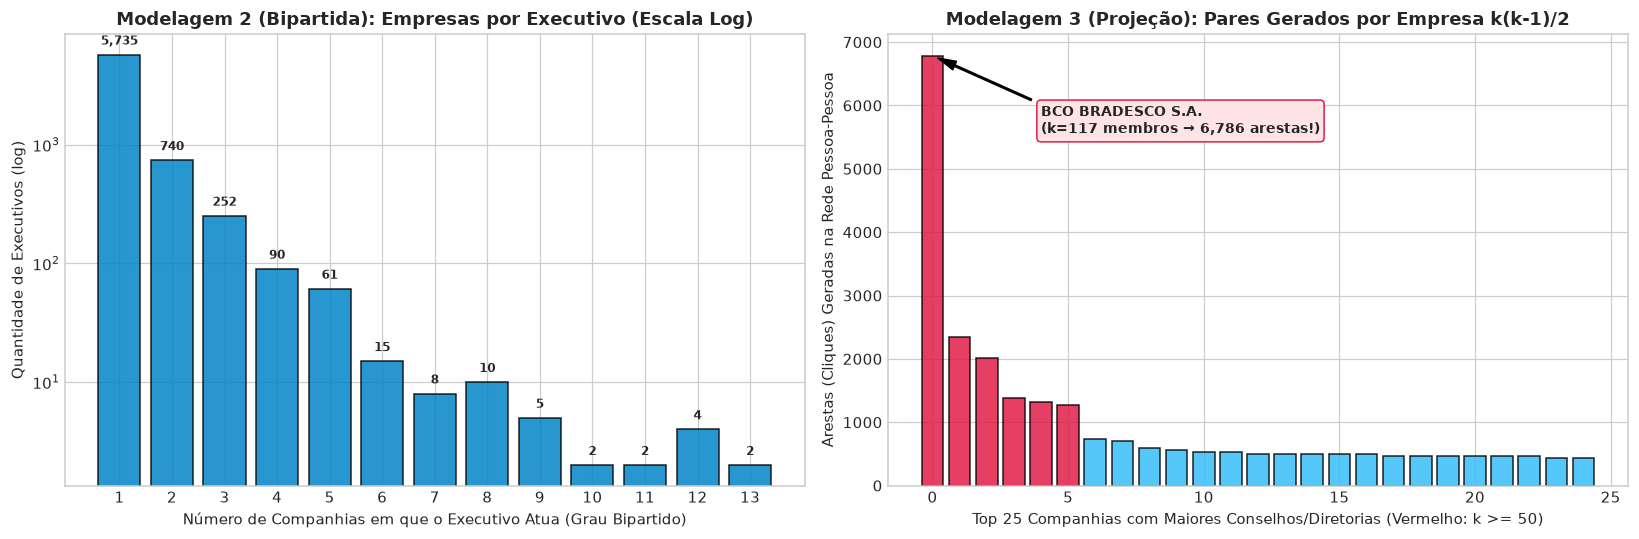

📌 Evidência do Artefato da Projeção (Semana 6): As 10% maiores companhias geram 47.9% de todos os pares da rede Pessoa–Pessoa.
📌 Apenas 1,191 dos 6,926 executivos (17.2%) atuam em 2 ou mais companhias e sustentam toda a conectividade inter-empresas!


In [4]:
# ==============================================================================
# VISUALIZAÇÃO DO EFEITO DAS ESCOLHAS DE MODELAGEM E O ARTEFATO DO CLIQUE
# ==============================================================================

# Calcula quantos executivos cada empresa possui (grau na partição de empresas do bipartido B)
tamanho_conselhos = pd.Series({c: B.degree(c) for c in unique_companies}).sort_values(ascending=False)
pares_gerados_por_empresa = tamanho_conselhos * (tamanho_conselhos - 1) // 2

# Calcula em quantas empresas cada executivo atua (grau na partição de pessoas do bipartido B)
mandatos_por_pessoa = pd.Series({p: B.degree(p) for p in unique_persons}).value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Painel 1: Distribuição de Mandatos por Executivo (Filtro do Bipartido)
barras = ax1.bar(mandatos_por_pessoa.index.astype(str), mandatos_por_pessoa.values, color="#0284c7", edgecolor="black", alpha=0.85)
ax1.set_yscale("log")
ax1.set_title("Modelagem 2 (Bipartida): Empresas por Executivo (Escala Log)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Número de Companhias em que o Executivo Atua (Grau Bipartido)", fontsize=10)
ax1.set_ylabel("Quantidade de Executivos (log)", fontsize=10)
for bar in barras:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval * 1.15, f"{int(yval):,}", ha='center', va='bottom', fontsize=8, fontweight='bold')

# Painel 2: O Artefato do Clique na Projeção Pessoa-Pessoa (k(k-1)/2)
top_25_empresas = pares_gerados_por_empresa.head(25)
cores_clique = ["#e11d48" if k >= 50 else "#38bdf8" for k in tamanho_conselhos.head(25)]
ax2.bar(range(len(top_25_empresas)), top_25_empresas.values, color=cores_clique, edgecolor="black", alpha=0.85)
ax2.set_title("Modelagem 3 (Projeção): Pares Gerados por Empresa k(k-1)/2", fontsize=12, fontweight="bold")
ax2.set_xlabel("Top 25 Companhias com Maiores Conselhos/Diretorias (Vermelho: k >= 50)", fontsize=10)
ax2.set_ylabel("Arestas (Cliques) Geradas na Rede Pessoa-Pessoa", fontsize=10)

# Destaca o caso extremo do Banco Bradesco (k=117 -> 6.786 arestas)
maior_emp = top_25_empresas.index[0]
maior_k = tamanho_conselhos.iloc[0]
maior_pares = top_25_empresas.iloc[0]
ax2.annotate(
    f"{maior_emp}\n(k={maior_k} membros → {maior_pares:,} arestas!)",
    xy=(0, maior_pares), xytext=(4, maior_pares * 0.82),
    arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
    fontsize=9, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", facecolor="#ffe4e6", edgecolor="#e11d48")
)

plt.tight_layout()
plt.show()

fator_10_pct = pares_gerados_por_empresa.head(len(unique_companies) // 10).sum() / pares_gerados_por_empresa.sum()
print(f"📌 Evidência do Artefato da Projeção (Semana 6): As 10% maiores companhias geram {fator_10_pct:.1%} de todos os pares da rede Pessoa–Pessoa.")
print(f"📌 Apenas {len(multi_conselheiros):,} dos {len(unique_persons):,} executivos ({len(multi_conselheiros)/len(unique_persons):.1%}) atuam em 2 ou mais companhias e sustentam toda a conectividade inter-empresas!")

## 4 · Análise da Rede: do Grafo Bipartido à Projeção de Newman

Com as 4 modelagens construídas, a análise segue um fio condutor curto, do dado mais próximo do bruto até a resposta à pergunta de pesquisa:

| Etapa | Rede | O que faz | Conteúdo do curso |
| :--- | :--- | :--- | :--- |
| **4.1 – 4.2** | Bipartida $B$ | Visualiza o backbone e mede conectividade, diâmetro e densidade | Visualização, componentes, caminhos mínimos |
| **4.3** | Projeção de Newman $G_N$ | Projeta Pessoa–Pessoa atenuando o artefato do clique e visualiza o resultado | Redes bipartidas e projeções |
| **4.4 – 4.7** | $G_N$ e $B$ | Ranqueia executivos, localiza pontes, valida por remoção e perfila o top 10 | Centralidade, caminhos mínimos, robustez |

> 💡 **Por que o backbone em 4.1?** Os 7.633 nós de $B$ formam um borrão ilegível; mais de 80% das pessoas atuam em uma única companhia e não conectam nada. O backbone (executivos com grau $\ge 2$ e suas companhias) preserva exatamente as peças que costuram o mercado.

### 4.1 · Visualização do Grafo Bipartido

In [5]:
# ==============================================================================
# 4.1 · VISUALIZAÇÃO DO GRAFO BIPARTIDO (BACKBONE DE MULTI-CONSELHEIROS)
# ==============================================================================
# Desenhar os 7.633 nós de B geraria um "borrão" ilegível. O backbone (executivos com
# grau >= 2 e suas empresas) preserva exatamente as peças que costuram o mercado.

# --- Funções auxiliares de desenho de redes em Plotly (reutilizadas nas próximas células) ---
LAYOUT_REDE = dict(
    template="plotly_white", height=760, hovermode="closest",
    xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"),
    legend=dict(orientation="h", yanchor="bottom", y=0.0, xanchor="left", x=0.0, itemsizing="constant"),
    margin=dict(l=10, r=10, t=60, b=10),
)

def trace_arestas(G, pos, cor="#64748b", largura=0.5, opacidade=0.25, arestas=None):
    """Todas as arestas em um único traço (segmentos separados por None)."""
    xs, ys = [], []
    for u, v in (G.edges() if arestas is None else arestas):
        xs += [pos[u][0], pos[v][0], None]
        ys += [pos[u][1], pos[v][1], None]
    return go.Scatter(x=xs, y=ys, mode="lines", line=dict(width=largura, color=cor), opacity=opacidade,
                      hoverinfo="skip", showlegend=False)

def trace_nos(G, pos, nos, nome, cor, simbolo, tamanhos, rotulos=None, extra_hover=None, borda="white"):
    """Nós de uma partição, com hover (nome e grau) e rótulos opcionais apenas para nós selecionados."""
    extra_hover = extra_hover or {}
    return go.Scatter(
        x=[pos[n][0] for n in nos], y=[pos[n][1] for n in nos],
        mode="markers+text" if rotulos else "markers",
        text=[rotulos.get(n, "") for n in nos] if rotulos else None,
        textposition="top center", textfont=dict(size=10, color="#0f172a"),
        marker=dict(size=tamanhos, color=cor, symbol=simbolo, opacity=0.9, line=dict(width=0.6, color=borda)),
        hovertext=[f"<b>{n}</b><br>{nome}<br>Grau: {G.degree(n)}{extra_hover.get(n, '')}" for n in nos],
        hoverinfo="text", name=nome,
    )

# --- Backbone do bipartido ---
componente_bb = max(nx.connected_components(B_backbone), key=len)
B_viz = B_backbone.subgraph(componente_bb)

pessoas_viz = [n for n in B_viz if B_viz.nodes[n]["tipo"] == "Pessoa"]
empresas_viz = [n for n in B_viz if B_viz.nodes[n]["tipo"] == "Empresa"]

pos = nx.spring_layout(B_viz, k=0.3, iterations=150, seed=42)

# Rótulos fixos apenas para os maiores nós de cada partição (os demais aparecem no hover)
top_emp_viz = sorted(empresas_viz, key=B_viz.degree, reverse=True)[:5]
top_pes_viz = sorted(pessoas_viz, key=B_viz.degree, reverse=True)[:3]
rotulos = {n: (n[:26] + "…" if len(n) > 26 else n) for n in top_emp_viz + top_pes_viz}

fig = go.Figure([
    trace_arestas(B_viz, pos),
    trace_nos(B_viz, pos, pessoas_viz, "Executivo (V_P)", "#0284c7", "circle",
              [min(4 + 1.2 * B_viz.degree(n), 14) for n in pessoas_viz], rotulos),
    trace_nos(B_viz, pos, empresas_viz, "Companhia (V_C)", "#e11d48", "square",
              [min(5 + 0.8 * B_viz.degree(n), 16) for n in empresas_viz], rotulos),
])
fig.update_layout(
    title=dict(text="<b>Modelagem 2 · Grafo Bipartido Pessoa–Empresa</b><br><sup>Componente gigante do backbone de multi-conselheiros (tamanho do nó = grau; passe o mouse para ver os nomes)</sup>"),
    **LAYOUT_REDE,
)
fig.show()

print(f"📌 Backbone desenhado: {len(pessoas_viz):,} executivos e {len(empresas_viz):,} companhias "
      f"({B_viz.number_of_edges():,} vínculos). Tamanho do nó = grau no backbone.")

📌 Backbone desenhado: 1,069 executivos e 512 companhias (2,957 vínculos). Tamanho do nó = grau no backbone.


### 4.2 · Conectividade, Diâmetro e Densidade
Três medidas globais respondem se o mercado é um bloco integrado ou um arquipélago: o **componente gigante** (GCC) mostra quanto da rede está conectada entre si; o **diâmetro** mostra a maior distância dentro dele; e a **densidade bipartida** $\frac{\vert E \vert}{\vert V_P \vert \cdot \vert V_C \vert}$ mostra que fração dos vínculos Pessoa–Empresa possíveis realmente existe.

In [6]:
# ==============================================================================
# 4.2 · CONECTIVIDADE, DIÂMETRO E DENSIDADE DO GRAFO BIPARTIDO
# ==============================================================================
componentes = sorted(nx.connected_components(B), key=len, reverse=True)
nos_gcc = componentes[0]
B_gcc = B.subgraph(nos_gcc)
pessoas_gcc = {n for n in nos_gcc if B.nodes[n]["tipo"] == "Pessoa"}
empresas_gcc = nos_gcc - pessoas_gcc

# Diâmetro exato do componente gigante (BFS a partir de cada nó; leva cerca de 1 min)
t0_diam = time.time()
diametro_gcc = nx.diameter(B_gcc)
t_diam = time.time() - t0_diam

resumo_conectividade = pd.DataFrame([
    {"Métrica": "Componentes conexos", "Valor": f"{len(componentes):,}"},
    {"Métrica": "Nós no componente gigante (GCC)", "Valor": f"{len(nos_gcc):,} ({len(nos_gcc) / B.number_of_nodes():.1%} da rede)"},
    {"Métrica": "  ↳ Executivos / Companhias no GCC", "Valor": f"{len(pessoas_gcc):,} / {len(empresas_gcc):,}"},
    {"Métrica": "  ↳ Companhias no GCC", "Valor": f"{len(empresas_gcc) / len(unique_companies):.1%} das {len(unique_companies):,}"},
    {"Métrica": "Tamanho dos 5 maiores componentes", "Valor": ", ".join(f"{len(c):,}" for c in componentes[:5])},
    {"Métrica": "Densidade bipartida de B", "Valor": f"{bipartite.density(B, unique_persons):.6f}"},
    {"Métrica": "Densidade bipartida do GCC", "Valor": f"{bipartite.density(B_gcc, pessoas_gcc):.6f}"},
    {"Métrica": "Diâmetro do GCC (arestas)", "Valor": f"{diametro_gcc}"},
])
display(resumo_conectividade)

print(f"📌 O GCC concentra {len(empresas_gcc) / len(unique_companies):.1%} das companhias: o mercado é um "
      f"'continente' com ilhas pequenas (o 2º maior componente tem {len(componentes[1])} nós).")
print(f"📌 Diâmetro = {diametro_gcc} arestas. Como o grafo é bipartido, cada 2 arestas equivalem a 1 salto "
      f"entre companhias (empresa → executivo → empresa). [diâmetro calculado em {t_diam:.0f}s]")

,Métrica,Valor
0,Componentes conexos,152
1,Nós no componente gigante (GCC),"6,029 (79.0% da rede)"
2,↳ Executivos / Companhias no GCC,"5,517 / 512"
3,↳ Companhias no GCC,72.4% das 707
4,Tamanho dos 5 maiores componentes,"6,029, 30, 29, 29, 27"
5,Densidade bipartida de B,0.001843
6,Densidade bipartida do GCC,0.002622
7,Diâmetro do GCC (arestas),24


📌 O GCC concentra 72.4% das companhias: o mercado é um 'continente' com ilhas pequenas (o 2º maior componente tem 30 nós).
📌 Diâmetro = 24 arestas. Como o grafo é bipartido, cada 2 arestas equivalem a 1 salto entre companhias (empresa → executivo → empresa). [diâmetro calculado em 53s]


### 4.3 · Projeção Pessoa–Pessoa de Newman

A projeção simples $G_P$ (Modelagem 3) trata igualmente dois colegas de um conselho de 117 membros e dois sócios de um conselho de 5. A **projeção de Newman** (*collaboration weighted*) corrige isso: cada empresa $c$ de tamanho $k_c$ contribui com peso $\frac{1}{k_c - 1}$ para cada par de seus membros,

$$w_{ij} = \sum_{c \,\in\, N(i) \cap N(j)} \frac{1}{k_c - 1}$$

A topologia é idêntica à de $G_P$ (mesmas arestas), mas conselhos grandes passam a ter laços individualmente fracos. Cada empresa com $k_c \ge 2$ injeta peso total $\binom{k_c}{2} \cdot \frac{1}{k_c - 1} = \frac{k_c}{2}$, o que gera a validação da célula: $\sum w_{ij} = \sum_{c:\,k_c \ge 2} k_c / 2$.

In [7]:
# ==============================================================================
# 4.3 · PROJEÇÃO PESSOA–PESSOA DE NEWMAN (COLLABORATION WEIGHTED)
# ==============================================================================
from plotly.subplots import make_subplots

# w_ij = soma, sobre as empresas c compartilhadas por i e j, de 1 / (k_c - 1)
G_newman = bipartite.collaboration_weighted_projected_graph(B, unique_persons)

# --- Validação (análoga à validação algébrica da Seção 3) ---------------------
# Cada empresa com k >= 2 membros gera k(k-1)/2 arestas de peso 1/(k-1), ou seja, peso total k/2.
# Logo: soma dos pesos = soma_{c : k_c >= 2} k_c / 2
peso_total = sum(w for _, _, w in G_newman.edges(data="weight"))
peso_esperado = sum(B.degree(c) / 2 for c in unique_companies if B.degree(c) >= 2)
assert G_newman.number_of_edges() == G_proj.number_of_edges(), "Newman e projeção simples devem ter a mesma topologia"
assert abs(peso_total - peso_esperado) < 1e-6, "Erro na validação do peso total de Newman"
print(f"✅ Validação OK: {G_newman.number_of_edges():,} arestas (mesma topologia de G_proj) | "
      f"peso total = {peso_total:,.1f} = Σ k_c/2 (empresas com k ≥ 2)")

# --- Efeito da ponderação sobre o artefato do clique --------------------------
k_emp = tamanho_conselhos[tamanho_conselhos >= 2]  # já ordenado de forma decrescente
n_top = len(unique_companies) // 10
share_arestas = (k_emp * (k_emp - 1) // 2).head(n_top).sum() / (k_emp * (k_emp - 1) // 2).sum()
share_peso = (k_emp / 2).head(n_top).sum() / (k_emp / 2).sum()

pesos_newman = [w for _, _, w in G_newman.edges(data="weight")]

fig = make_subplots(
    rows=1, cols=2, column_widths=[0.55, 0.45], horizontal_spacing=0.12,
    subplot_titles=("Distribuição dos pesos de Newman nas arestas de G_P",
                    f"Parcela gerada pelos 10% maiores conselhos ({n_top} empresas)"),
)
fig.add_trace(go.Histogram(x=pesos_newman, nbinsx=60, marker=dict(color="#0284c7", line=dict(width=1, color="black")),
                           opacity=0.85, name="Arestas", hovertemplate="peso ≈ %{x}<br>%{y:,} arestas<extra></extra>"), row=1, col=1)
fig.add_trace(go.Bar(x=["Arestas<br>(projeção simples)", "Peso total<br>(Newman)"], y=[share_arestas, share_peso],
                     marker=dict(color=["#e11d48", "#0284c7"], line=dict(width=1, color="black")), opacity=0.85,
                     text=[f"{share_arestas:.1%}", f"{share_peso:.1%}"], textposition="outside", textfont=dict(size=13),
                     hovertemplate="%{x}: %{y:.1%}<extra></extra>", showlegend=False), row=1, col=2)
fig.update_yaxes(type="log", dtick=1, exponentformat="power", title_text="Quantidade de arestas (log)", row=1, col=1)
fig.update_xaxes(title_text="Peso w(i, j) = Σ 1 / (k_c − 1)", row=1, col=1)
fig.update_yaxes(range=[0, 1.12], tickvals=[0, 0.2, 0.4, 0.6, 0.8, 1], tickformat=".0%", title_text="Fração do total", row=1, col=2)
fig.update_layout(template="plotly_white", height=450, showlegend=False, bargap=0.4)
fig.show()

print(f"📌 Na projeção simples, os 10% maiores conselhos geram {share_arestas:.1%} das arestas; "
      f"na projeção de Newman, respondem por {share_peso:.1%} do peso total.")

✅ Validação OK: 75,705 arestas (mesma topologia de G_proj) | peso total = 4,510.5 = Σ k_c/2 (empresas com k ≥ 2)


📌 Na projeção simples, os 10% maiores conselhos geram 47.9% das arestas; na projeção de Newman, respondem por 23.9% do peso total.


#### 4.3.1 · Visualização da Projeção de Newman
Os $6.9$ mil nós de $G_N$ e suas $\approx 75$ mil arestas formariam um borrão, e a maioria dos executivos (uma única companhia) só forma cliques periféricos. Desenhamos o subgrafo induzido pelos **multi-conselheiros** ($B$-grau $\ge 2$), com arestas separadas em três faixas de peso de Newman. Não aplicamos corte por peso: laços fracos vindos de conselhos grandes são justamente os que mantêm o componente gigante conectado.

In [8]:
# ==============================================================================
# 4.3.1 · VISUALIZAÇÃO DA PROJEÇÃO DE NEWMAN (REDE DE MULTI-CONSELHEIROS)
# ==============================================================================
# Mais de 80% dos executivos atuam em uma única companhia e só formam cliques periféricos; o que conecta o
# mercado é o subgrafo induzido pelos multi-conselheiros (grau >= 2 em B).
multi_conselheiros_n = [p for p in unique_persons if B.degree(p) >= 2]
G_N_viz = G_newman.subgraph(multi_conselheiros_n)
G_N_viz = G_N_viz.subgraph(max(nx.connected_components(G_N_viz), key=len))

# Layout ponderado: laços mais fortes (peso maior) aproximam os executivos
pos_n = nx.spring_layout(G_N_viz, weight="weight", k=0.15, iterations=150, seed=42)

# Arestas agrupadas em 3 faixas de peso (a espessura/opacidade cresce com a força do laço)
faixas = [("Laço fraco (w < 0,1)", 0.0, 0.1, 0.4, 0.12), ("Laço médio (0,1 ≤ w < 0,5)", 0.1, 0.5, 0.9, 0.35),
          ("Laço forte (w ≥ 0,5)", 0.5, float("inf"), 1.8, 0.8)]
tracos = []
for rotulo_faixa, lo, hi, larg, opac in faixas:
    arestas_f = [(u, v) for u, v, w in G_N_viz.edges(data="weight") if lo <= w < hi]
    tr = trace_arestas(G_N_viz, pos_n, cor="#475569", largura=larg, opacidade=opac, arestas=arestas_f)
    tr.update(name=f"{rotulo_faixa}: {len(arestas_f):,}", showlegend=True)
    tracos.append(tr)

nos_n = list(G_N_viz.nodes)
cargos = {p: B.degree(p) for p in nos_n}
top_n = sorted(nos_n, key=lambda p: cargos[p], reverse=True)[:5]
rot_n = {p: " ".join([p.split()[0].title(), p.split()[-1].title()]) for p in top_n}
hover_n = {p: f"<br>Companhias: {cargos[p]}<br>Força de Newman: {G_N_viz.degree(p, weight='weight'):.2f}" for p in nos_n}

fig = go.Figure(tracos)
fig.add_trace(go.Scatter(
    x=[pos_n[p][0] for p in nos_n], y=[pos_n[p][1] for p in nos_n],
    mode="markers+text", text=[rot_n.get(p, "") for p in nos_n], textposition="top center", textfont=dict(size=10),
    marker=dict(size=[5 + 2.2 * cargos[p] for p in nos_n], color=[cargos[p] for p in nos_n], colorscale="Viridis",
                showscale=True, colorbar=dict(title="Companhias<br>por executivo", len=0.6),
                opacity=0.9, line=dict(width=0.6, color="white")),
    hovertext=[f"<b>{p}</b>{hover_n[p]}" for p in nos_n], hoverinfo="text", name="Executivo", showlegend=False,
))
fig.update_layout(
    title=dict(text="<b>Modelagem 3 · Projeção de Newman Pessoa–Pessoa</b><br><sup>Componente gigante entre multi-conselheiros (cor e tamanho = nº de companhias; arestas por faixa de peso de Newman)</sup>"),
    **LAYOUT_REDE,
)
fig.show()

print(f"📌 {G_N_viz.number_of_nodes():,} executivos e {G_N_viz.number_of_edges():,} laços desenhados. "
      f"Laços fortes (w ≥ 0,5) são raros e vêm de conselhos pequenos ou de pares que dividem várias companhias.")

📌 1,069 executivos e 7,717 laços desenhados. Laços fortes (w ≥ 0,5) são raros e vêm de conselhos pequenos ou de pares que dividem várias companhias.


### 4.4 · Quem são os executivos que conectam o mercado?

Comparamos três critérios de importância para cada executivo:
1. **Nº de companhias** (grau em $B$): a medida ingênua.
2. **Força na projeção simples:** soma dos pesos em $G_P$ (sofre com o artefato do clique).
3. **Betweenness ponderado em $G_N$:** fração dos caminhos mínimos entre pares de executivos que passam por ele, com **distância $= 1/w_{ij}$** (laços fortes aproximam). É a medida de ponte.

> ⚠️ **Propriedade da normalização de Newman:** a *força* de um executivo em $G_N$ é exatamente o número de companhias em que atua, pois cada empresa contribui com $(k_c - 1) \cdot \frac{1}{k_c - 1} = 1$. Por isso a força de Newman não aparece como critério: ela repete o grau. O ganho da projeção está nas **distâncias**, usadas pelo betweenness.
>
> ⏱️ O betweenness exato em 6,9 mil nós leva alguns minutos; usamos amostragem de pivôs com semente fixa (`K_AMOSTRAS`) para reprodutibilidade. Para o cálculo exato, defina `K_AMOSTRAS = None`.

In [9]:
# ==============================================================================
# 4.4 · RANKING DOS EXECUTIVOS: GRAU, FORÇA SIMPLES E BETWEENNESS PONDERADO (NEWMAN)
# ==============================================================================
# Caminho mínimo na projeção de Newman: laços mais fortes (peso maior) = distâncias menores.
for _, _, d in G_newman.edges(data=True):
    d["distancia"] = 1.0 / d["weight"]

# Betweenness exato em 6.9k nós leva ~5 min; amostramos K pivôs (seed fixa) para reproduzir em ~1 min.
K_AMOSTRAS = None  # use None para o cálculo exato
t0_bt = time.time()
betweenness = nx.betweenness_centrality(G_newman, k=K_AMOSTRAS, weight="distancia", normalized=True, seed=42)
t_bt = time.time() - t0_bt

df_exec = pd.DataFrame({
    "empresas": pd.Series({p: B.degree(p) for p in unique_persons}),
    "forca_simples": pd.Series(dict(G_proj.degree(weight="weight"))),
    "forca_newman": pd.Series(dict(G_newman.degree(weight="weight"))),
    "betweenness": pd.Series(betweenness),
})
print(f"✅ Métricas calculadas para {len(df_exec):,} executivos (betweenness com k={K_AMOSTRAS} pivôs em {t_bt:.0f}s).")

# --- Propriedade da normalização de Newman -----------------------------------
# Cada empresa c (k_c >= 2) contribui com (k_c - 1) vizinhos de peso 1/(k_c - 1) = 1 ao grau ponderado
# de cada membro. Logo, a FORÇA de Newman = nº de companhias com ao menos 2 membros: ela não traz
# informação nova sobre o grau bipartido. O ganho da projeção está nas DISTÂNCIAS (betweenness).
empresas_k2 = pd.Series({p: sum(1 for c in B.neighbors(p) if B.degree(c) >= 2) for p in unique_persons})
assert np.allclose(df_exec["forca_newman"], empresas_k2.reindex(df_exec.index)), "Força de Newman deveria igualar o grau bipartido"
print("✅ Propriedade verificada: força de Newman de cada executivo = nº de companhias com ≥ 2 membros.")

# Os 3 rankings lado a lado (top 8 de cada critério)
criterios = {
    "Nº de empresas (grau em B)": "empresas",
    "Força na projeção simples": "forca_simples",
    "Betweenness ponderado (Newman)": "betweenness",
}
tabela_top = pd.DataFrame({
    nome: [f"{n[:30]}" for n in df_exec.sort_values([col, "empresas"], ascending=False).head(8).index]
    for nome, col in criterios.items()
}, index=range(1, 9))
tabela_top.index.name = "Posição"
display(tabela_top)

print("\n📐 Correlação de Spearman entre os critérios:")
display(df_exec[["empresas", "forca_simples", "betweenness"]].corr(method="spearman").round(2))

✅ Métricas calculadas para 6,926 executivos (betweenness com k=None pivôs em 305s).
✅ Propriedade verificada: força de Newman de cada executivo = nº de companhias com ≥ 2 membros.


,Nº de empresas (grau em B),Força na projeção simples,Betweenness ponderado (Newman)
Posição,,,
1,ANDRÉ PIRES DE OLIVEIRA DIAS,MARIA ELVIRA LOPES GIMENEZ,MARIA ELVIRA LOPES GIMENEZ
2,MARIA ELVIRA LOPES GIMENEZ,VANDERLEI DOMINGUEZ DA ROSA,MURICI DOS SANTOS
3,RADAMÉS ANDRADE CASSEB,LUIZ CARLOS TRABUCO CAPPI,CARLA ALESSANDRA TREMATORE
4,ROBERTO BORGES PAIVA,JOÃO VICENTE SILVA MACHADO,PAULO ROBERTO FRANCESCHI
5,RODRIGO JOSÉ DE PONTES SEABRA,MARCOS APARECIDO GALENDE,MARCELO CURTI
6,YAROSLAV MEMRAVA NETO,ALEXANDRE DA SILVA GLÜHER,VANDERLEI DOMINGUEZ DA ROSA
7,MARCELLO GUIDOTTI,MAURÍCIO MACHADO DE MINAS,GABRIELA SOARES PEDERCINI
8,RICARDO PEREZ BOTELHO,MARCELO CURTI,RAPHAEL MANHÃES MARTINS



📐 Correlação de Spearman entre os critérios:


,empresas,forca_simples,betweenness
empresas,1.00,0.44,0.91
forca_simples,0.44,1.00,0.45
betweenness,0.91,0.45,1.00


### 4.5 · Pontes Estruturais: Cargos × Betweenness
O gráfico cruza o número de cargos com o papel de ponte. Quem está acima da tendência dos demais executivos com o mesmo número de cargos conecta partes do mercado que de outro modo ficariam distantes.

In [10]:
# ==============================================================================
# 4.5 · PONTES ESTRUTURAIS: NÚMERO DE CARGOS × BETWEENNESS
# ==============================================================================
multi = df_exec[(df_exec["empresas"] >= 2) & (df_exec["betweenness"] > 0)].copy()
top_ponte = multi.sort_values("betweenness", ascending=False).head(10)

rng = np.random.default_rng(42)
x_jitter = multi["empresas"] + rng.uniform(-0.2, 0.2, len(multi))

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=x_jitter, y=multi["betweenness"], mode="markers", name="Multi-conselheiros",
    marker=dict(color="#0284c7", size=6, opacity=0.5),
    hovertext=[f"<b>{n}</b><br>Companhias: {r.empresas}<br>Betweenness: {r.betweenness:.5f}" for n, r in multi.iterrows()],
    hoverinfo="text",
))

# Top 10 destacado, numerado no gráfico e listado na caixa de texto
legenda_top = []
for i, (nome, linha) in enumerate(top_ponte.iterrows(), start=1):
    partes = nome.split()
    legenda_top.append(f"{i}. {partes[0].title()} {partes[-1].title()}" if len(partes) > 1 else f"{i}. {nome.title()}")
fig.add_trace(go.Scatter(
    x=top_ponte["empresas"], y=top_ponte["betweenness"], mode="markers+text", name="Top 10 betweenness",
    text=[str(i) for i in range(1, 11)],
    textposition=["top right", "top left", "bottom right", "bottom left"] * 3, textfont=dict(color="#e11d48", size=12),
    marker=dict(size=15, color="rgba(0,0,0,0)", line=dict(width=2, color="#e11d48")),
    hovertext=[f"<b>{n}</b><br>Companhias: {r.empresas}<br>Betweenness: {r.betweenness:.5f}" for n, r in top_ponte.iterrows()],
    hoverinfo="text",
))
fig.add_annotation(xref="paper", yref="paper", x=0.98, y=0.55, xanchor="right", yanchor="top", showarrow=False,
                   text="<b>Top 10 por betweenness</b><br>" + "<br>".join(legenda_top), align="left",
                   bordercolor="#e11d48", borderwidth=1, borderpad=6, bgcolor="rgba(255,255,255,0.9)", font=dict(size=11))
fig.update_layout(
    template="plotly_white", height=560,
    title=dict(text="<b>Número de cargos × papel de ponte</b><br><sup>Executivos com 2 ou mais companhias</sup>"),
    xaxis=dict(title="Número de companhias em que o executivo atua (grau no grafo bipartido)", dtick=1),
    yaxis=dict(title="Betweenness ponderado na projeção de Newman (log)", type="log", dtick=1, exponentformat="power"),
    legend=dict(orientation="h", yanchor="bottom", y=1.0, xanchor="right", x=1.0),
)
fig.show()

# Pontes de "baixo grau": maiores betweenness entre quem atua em no máximo 3 companhias
pct = multi["betweenness"].rank(pct=True)
baixo_grau = multi[multi["empresas"] <= 3].sort_values("betweenness", ascending=False).head(5)
print(f"📌 Correlação de Spearman grau × betweenness = {df_exec[['empresas', 'betweenness']].corr(method='spearman').iloc[0, 1]:.2f}: "
      f"o número de cargos explica boa parte do papel de ponte, mas não tudo.")
print("📌 Maiores pontes entre quem atua em no máximo 3 companhias:")
for nome, linha in baixo_grau.iterrows():
    print(f"   • {nome[:34]:<34} | {int(linha['empresas'])} cias | betweenness no percentil {pct[nome]:.1%} dos multi-conselheiros")

📌 Correlação de Spearman grau × betweenness = 0.91: o número de cargos explica boa parte do papel de ponte, mas não tudo.
📌 Maiores pontes entre quem atua em no máximo 3 companhias:
   • RAQUEL WILLE SARQUIS               | 3 cias | betweenness no percentil 98.9% dos multi-conselheiros
   • ROBERTO PEDOTE                     | 2 cias | betweenness no percentil 98.7% dos multi-conselheiros
   • ANTONIO KANDIR                     | 3 cias | betweenness no percentil 98.6% dos multi-conselheiros
   • FERNANDO DAL-RI MURCIA             | 3 cias | betweenness no percentil 97.9% dos multi-conselheiros
   • MARCELO FARIA DE LIMA              | 3 cias | betweenness no percentil 97.7% dos multi-conselheiros


### 4.6 · Validação Estrutural por Remoção de Executivos
Um ranking só é útil se tiver consequência estrutural. Removemos de $B$ os 150 principais executivos por cada critério e acompanhamos a fração das companhias que permanece no componente gigante. Como linha de base, removemos o mesmo número de multi-conselheiros **ao acaso** (10 sorteios). Se o betweenness identifica pontes, a rede deve se fragmentar mais rápido com ele do que com o grau ou com o acaso.

In [11]:
# ==============================================================================
# 4.6 · VALIDAÇÃO ESTRUTURAL: ROBUSTEZ DA REDE À REMOÇÃO DE EXECUTIVOS
# ==============================================================================
# Se o betweenness identifica de fato as "pontes", retirar esses executivos deve fragmentar o
# componente gigante mais rápido do que retirar o mesmo número de executivos ao acaso.
total_cias = len(unique_companies)
N_REMOVER, PASSO, N_SORTEIOS = 150, 10, 10

def curva_remocao(ordem):
    """Fração de companhias no maior componente após remover os executivos de `ordem` (em lotes de PASSO)."""
    H = B.copy()
    curva = []
    for i in range(0, N_REMOVER + 1, PASSO):
        if i > 0:
            H.remove_nodes_from(ordem[i - PASSO:i])
        gcc_h = max(nx.connected_components(H), key=len)
        curva.append(sum(1 for n in gcc_h if H.nodes[n]["tipo"] == "Empresa") / total_cias)
    return curva

ordem_bt = list(df_exec.sort_values("betweenness", ascending=False).index[:N_REMOVER])
ordem_grau = list(df_exec.sort_values(["empresas", "betweenness"], ascending=False).index[:N_REMOVER])
candidatos = list(df_exec[df_exec["empresas"] >= 2].index)

rng = np.random.default_rng(42)
curvas_aleatorias = np.array([curva_remocao(list(rng.permutation(candidatos)[:N_REMOVER])) for _ in range(N_SORTEIOS)])

x_rem = list(range(0, N_REMOVER + 1, PASSO))
curva_bt, curva_grau = curva_remocao(ordem_bt), curva_remocao(ordem_grau)

fig = go.Figure()
# Faixa entre o mínimo e o máximo dos sorteios aleatórios
fig.add_trace(go.Scatter(x=x_rem, y=curvas_aleatorias.max(axis=0), mode="lines", line=dict(width=0), hoverinfo="skip", showlegend=False))
fig.add_trace(go.Scatter(x=x_rem, y=curvas_aleatorias.min(axis=0), mode="lines", line=dict(width=0), fill="tonexty",
                         fillcolor="rgba(100,116,139,0.18)", hoverinfo="skip", name="Faixa min–máx dos sorteios"))
fig.add_trace(go.Scatter(x=x_rem, y=curvas_aleatorias.mean(axis=0), mode="lines+markers", name=f"Remoção aleatória (média de {N_SORTEIOS} sorteios)",
                         line=dict(color="#64748b", dash="dot"), marker=dict(symbol="triangle-up", size=8)))
fig.add_trace(go.Scatter(x=x_rem, y=curva_grau, mode="lines+markers", name="Remoção por nº de empresas",
                         line=dict(color="#0284c7", dash="dash"), marker=dict(symbol="square", size=8)))
fig.add_trace(go.Scatter(x=x_rem, y=curva_bt, mode="lines+markers", name="Remoção por betweenness (Newman)",
                         line=dict(color="#e11d48"), marker=dict(symbol="circle", size=8)))
fig.update_layout(
    template="plotly_white", height=520, hovermode="x unified",
    title=dict(text="<b>Robustez do grafo bipartido: ataque a pontes vs. falha aleatória</b>"),
    xaxis=dict(title="Executivos removidos (apenas multi-conselheiros no sorteio)"),
    yaxis=dict(title="Fração das companhias no componente gigante", range=[0, max(curva_bt[0], 0.01) * 1.05], tickformat=".0%"),
    legend=dict(orientation="h", yanchor="bottom", y=-0.35, xanchor="left", x=0.0),
)
fig.show()

print(f"📌 Sem remoções, o GCC reúne {curva_bt[0]:.1%} das companhias. Após remover {N_REMOVER} executivos: "
      f"betweenness → {curva_bt[-1]:.1%} | nº de empresas → {curva_grau[-1]:.1%} | aleatório → {curvas_aleatorias.mean(axis=0)[-1]:.1%}.")

📌 Sem remoções, o GCC reúne 72.4% das companhias. Após remover 150 executivos: betweenness → 59.4% | nº de empresas → 60.8% | aleatório → 69.3%.


### 4.7 · Perfil dos Conectores e Ego-network
Tabela com os 10 maiores conectores (profissão, órgãos em que atuam e algumas de suas companhias) e a ego-network bipartida dos 3 primeiros, que mostra graficamente como cada um liga grupos de companhias que, sem ele, ficariam separados.

In [12]:
# ==============================================================================
# 4.7 · PERFIL DOS PRINCIPAIS CONECTORES E EGO-NETWORK DO TOP 3
# ==============================================================================
def simplificar_orgaos(texto):
    """Reduz a descrição longa do órgão da CVM a rótulos curtos."""
    t = texto.lower()
    rotulos_orgao = [rot for chave, rot in [("fiscal", "Fiscal"), ("administra", "Administração"), ("diretoria", "Diretoria")] if chave in t]
    return rotulos_orgao or ["Outro"]

mandatos_top = cleaned_df[cleaned_df["Person_Name"].isin(top_ponte.index)]
profissao_comum = mandatos_top.groupby("Person_Name")["Profissao"].agg(
    lambda s: s.dropna().mode().iloc[0] if s.notna().any() else "—"
)
orgaos_top = mandatos_top.groupby("Person_Name")["Orgao"].agg(
    lambda s: " + ".join(sorted({r for o in s for r in simplificar_orgaos(o)}))
)

perfil = top_ponte.drop(columns="forca_newman").copy()
perfil["profissao"] = profissao_comum
perfil["orgaos"] = orgaos_top
perfil["companhias"] = [
    ", ".join(sorted(c[:22] for c in B.neighbors(p))[:3]) + (f" (+{B.degree(p) - 3})" if B.degree(p) > 3 else "")
    for p in perfil.index
]
perfil["betweenness"] = perfil["betweenness"].map("{:.4f}".format)
perfil["forca_simples"] = perfil["forca_simples"].round(1)
perfil.index = [n[:34] for n in perfil.index]
display(perfil[["empresas", "betweenness", "profissao", "orgaos", "companhias"]])

# --- Ego-network dos 3 maiores conectores no grafo bipartido -------------------
top3 = list(top_ponte.index[:3])
empresas_ego = {e for p in top3 for e in B.neighbors(p)}
colegas_ego = {p for e in empresas_ego for p in B.neighbors(e) if B.degree(p) >= 2}
B_ego = B.subgraph(set(top3) | empresas_ego | colegas_ego)

pos_ego = nx.spring_layout(B_ego, k=0.25, iterations=100, seed=42)
colegas_so = [n for n in colegas_ego if n not in top3]
empresas_ego_l = list(empresas_ego)
rot = {p: p.title()[:28] for p in top3}
rot.update({e: (e[:24] + "…" if len(e) > 24 else e) for e in empresas_ego if B_ego.degree(e) >= 8})

fig = go.Figure([
    trace_arestas(B_ego, pos_ego),
    trace_nos(B_ego, pos_ego, colegas_so, "Outros multi-conselheiros", "#38bdf8", "circle", 7),
    trace_nos(B_ego, pos_ego, empresas_ego_l, "Companhias", "#e11d48", "square", 11, rotulos=rot),
    trace_nos(B_ego, pos_ego, top3, "Top 3 conectores", "#facc15", "star", 26, rotulos=rot, borda="black"),
])
fig.update_layout(
    title=dict(text="<b>Ego-network bipartida dos 3 maiores conectores</b><br><sup>Ranking por betweenness ponderado na projeção de Newman</sup>"),
    **LAYOUT_REDE,
)
fig.show()
print(f"📌 Os 3 conectores tocam {len(empresas_ego)} companhias e compartilham o comando com {len(colegas_so):,} outros multi-conselheiros.")

,empresas,betweenness,profissao,orgaos,companhias
MARIA ELVIRA LOPES GIMENEZ,13,0.0728,Economista,Fiscal,"BICICLETAS MONARK S.A., CIA BRASILEIRA DE DIST..."
MURICI DOS SANTOS,9,0.0567,Advogado,Fiscal,"CAMIL ALIMENTOS S.A., D1000 VAREJO FARMA PAR, ..."
CARLA ALESSANDRA TREMATORE,8,0.0447,Contadora,Administração + Fiscal,"ALLIED TECNOLOGIA S.A., ANIMA HOLDING S.A., BR..."
PAULO ROBERTO FRANCESCHI,8,0.0427,Contador,Fiscal,"AXIA ENERGIA S.A., BANCO DO ESTADO DO RIO, BRA..."
MARCELO CURTI,9,0.0383,Economista,Administração + Fiscal,"CIA GAS DE SAO PAULO -, COGNA EDUCAÇÃO S.A., C..."
VANDERLEI DOMINGUEZ DA ROSA,10,0.0329,Contador,Fiscal,"BRADSAÚDE S.A., CIA ESTADUAL DE DISTRI, CIA SA..."
GABRIELA SOARES PEDERCINI,5,0.0316,Engenheira Eletricista,Administração + Fiscal,"BCO ABC BRASIL S.A., CIA CATARINENSE DE AGU, C..."
RAPHAEL MANHÃES MARTINS,5,0.0305,Advogado,Administração + Fiscal,"AMERICANAS S.A. - EM R, BRADESPAR S.A., EMBRAE..."
RODOLFO VILLELA MARINO,6,0.0279,Administrador de Empresas,Administração + Diretoria,"AEGEA SANEAMENTO E PAR, ALPARGATAS S.A., DEXCO..."
ELIAS DE MATOS BRITO,7,0.0271,Contador,Administração + Fiscal,"AMERICANAS S.A. - EM R, CIA PARTICIPACOES ALIA..."


📌 Os 3 conectores tocam 30 companhias e compartilham o comando com 136 outros multi-conselheiros.
